### importar las librerías necesarias

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from torchvision.datasets import MNIST as M
from pathlib import Path
import urllib.request
p=print
d=display

### ver dónde estamos parados y crear las carpetas donde se guardarán las descargas

In [2]:
p("Donde estoy: ", Path.cwd())

Donde estoy:  /home/Ian/prediccion_red/cuadernos


In [3]:
p("A donde me dirigira el (.parent): ", Path.cwd().parent)

A donde me dirigira el (.parent):  /home/Ian/prediccion_red


In [4]:
Carpeta_Proyecto= Path.cwd().parent
Carpeta_descargas= Carpeta_Proyecto/"Dataset"/"Descargados"
Carpeta_descargas.mkdir(parents=True, exist_ok=True)# acá se da la orden de crear la carpeta y además
# si en futuro le doy a ejecutar o correr o reinicio de kernel no me daria problemas. 
#es decir nose duplicara simplemente se salteara

In [5]:
p(Carpeta_descargas)

/home/Ian/prediccion_red/Dataset/Descargados


### descargar los datos de MNIST

In [6]:
M_entrenar = M(root=Carpeta_descargas, train=True, download=True)
p(M_entrenar)

Dataset MNIST
    Number of datapoints: 60000
    Root location: /home/Ian/prediccion_red/Dataset/Descargados
    Split: Train


In [7]:
M_prueba= M(root=Carpeta_descargas, train=False, download=True)
p(M_prueba)

Dataset MNIST
    Number of datapoints: 10000
    Root location: /home/Ian/prediccion_red/Dataset/Descargados
    Split: Test


### mostrar una imagen como matriz de números y como dibujo

In [16]:
imagen = M_entrenar.data[0].numpy()
p("Cuadrícula de imagen 28*28:\n", imagen)
p(imagen.shape)

Cuadrícula de imagen 28*28:
 [[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136
  175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253
  225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251
   93  82  82  56  39   0   0   0   0   0]
 [  0   0   0   0   0   0   0  18 2

In [17]:
r_i = M_entrenar.targets[0].item()
p(r_i)

5


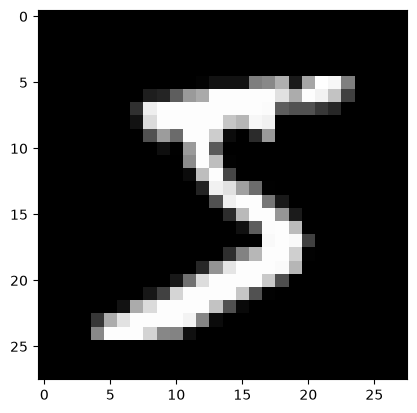

In [10]:
plt.imshow(imagen, cmap="gray")
plt.show()


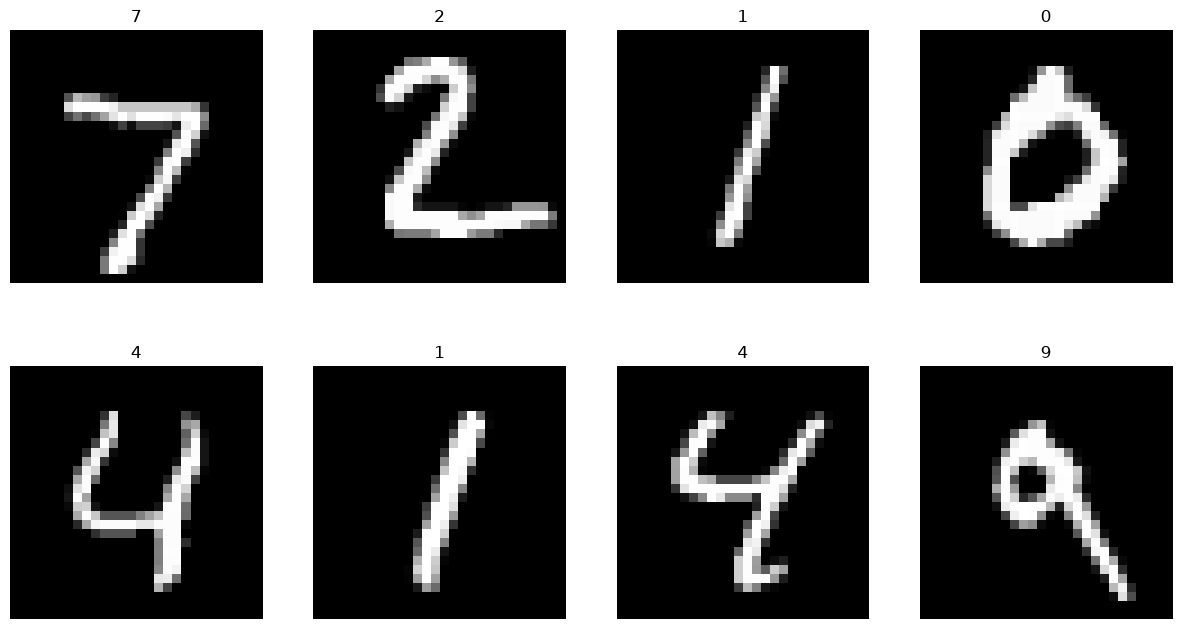

In [24]:
plt.figure(figsize=(15, 8))

for i in range(8):
    imagen = M_prueba.data[i].numpy()
    r_i = M_prueba.targets[i].item()

    plt.subplot(2, 4, i + 1)
    plt.imshow(imagen, cmap="gray")
    plt.title(r_i)
    plt.axis("off")

plt.show()

### convertir el arreglo de NumPy en una tabla plana de pandas

In [26]:
df_e=pd.DataFrame(M_entrenar.data.numpy().reshape(60000, 784))
df_e["respuesta"]=M_entrenar.targets.numpy()
df_e.head(5)

,0,1,2,3,4,5,6,7,8,9,...,775,776,777,778,779,780,781,782,783,respuesta
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,5
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,4
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,9


In [29]:
df_e.shape

(60000, 785)

In [31]:
df_p = pd.DataFrame(M_prueba.data.numpy().reshape(10000, 784))
df_p["respuesta"] = M_prueba.targets.numpy()
df_p.head()

,0,1,2,3,4,5,6,7,8,9,...,775,776,777,778,779,780,781,782,783,respuesta
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,7
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,2
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,4


In [32]:
df_p.shape

(10000, 785)

In [42]:
d(df_e.describe())
p("\n******************************************************************************************************-*****--")
d(df_p.describe())

,0,1,2,3,4,5,6,7,8,9,...,775,776,777,778,779,780,781,782,783,respuesta
count,60000.0,60000.0,60000.0,60000.0,60000.0,60000.0,60000.0,60000.0,60000.0,60000.0,...,60000.000000,60000.000000,60000.000000,60000.000000,60000.0000,60000.0,60000.0,60000.0,60000.0,60000.000000
mean,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.088867,0.045633,0.019283,0.015117,0.0020,0.0,0.0,0.0,0.0,4.453933
std,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,3.956189,2.839845,1.686770,1.678283,0.3466,0.0,0.0,0.0,0.0,2.889270
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.0000,0.0,0.0,0.0,0.0,0.000000
25%,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.0000,0.0,0.0,0.0,0.0,2.000000
50%,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.0000,0.0,0.0,0.0,0.0,4.000000
75%,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.0000,0.0,0.0,0.0,0.0,7.000000
max,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,254.000000,253.000000,253.000000,254.000000,62.0000,0.0,0.0,0.0,0.0,9.000000



******************************************************************************************************-*****--


,0,1,2,3,4,5,6,7,8,9,...,775,776,777,778,779,780,781,782,783,respuesta
count,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,...,10000.000000,10000.000000,10000.0000,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.000000
mean,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.163600,0.052600,0.0006,0.0,0.0,0.0,0.0,0.0,0.0,4.443400
std,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,5.736072,2.420004,0.0600,0.0,0.0,0.0,0.0,0.0,0.0,2.895865
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
25%,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,2.000000
50%,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,4.000000
75%,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,7.000000
max,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,253.000000,156.000000,6.0000,0.0,0.0,0.0,0.0,0.0,0.0,9.000000


In [50]:
p(df_e.isnull().sum())
p("\n")
p("*-."*40)
p("\n")
p(df_p.isnull().sum())

0            0
1            0
2            0
3            0
4            0
            ..
780          0
781          0
782          0
783          0
respuesta    0
Length: 785, dtype: int64


*-.*-.*-.*-.*-.*-.*-.*-.*-.*-.*-.*-.*-.*-.*-.*-.*-.*-.*-.*-.*-.*-.*-.*-.*-.*-.*-.*-.*-.*-.*-.*-.*-.*-.*-.*-.*-.*-.*-.*-.


0            0
1            0
2            0
3            0
4            0
            ..
780          0
781          0
782          0
783          0
respuesta    0
Length: 785, dtype: int64


In [51]:
p("Entrenamiento:", df_e.shape)
p("Prueba:", df_p.shape)

Entrenamiento: (60000, 785)
Prueba: (10000, 785)


### separar en X e Y

In [52]:
Xtr = df_e.drop(columns="respuesta")
Ytr = df_e["respuesta"]
Xts = df_p.drop(columns="respuesta")
Yts = df_p["respuesta"]

p("Datos de entrenamiento: ", len(Xtr))
p("Datos de prueba: ", len(Xts))

Datos de entrenamiento:  60000
Datos de prueba:  10000


### MNIST: guardar las tablas de entrenamiento

In [53]:
Carpeta_listos = Carpeta_Proyecto/"Dataset"/"M_Listos"
Carpeta_listos.mkdir(parents=True, exist_ok=True)
p(Carpeta_listos)

/home/Ian/prediccion_red/Dataset/M_Listos


### guardar

In [54]:
df_e.to_csv(Carpeta_listos/"M_entre.csv", index=False)
df_p.to_csv(Carpeta_listos/"M_prueb.csv", index=False)
p("Guardado")

Guardado


# EMNIST: letras

In [58]:
from torchvision.datasets import EMNIST as E

### descargar los datos de EMNIST

In [57]:
E_entrenar = E(root=Carpeta_descargas, split="balanced", train=True, download=True)
p(E_entrenar)

Dataset EMNIST
    Number of datapoints: 112800
    Root location: /home/Ian/prediccion_red/Dataset/Descargados
    Split: Train


In [61]:
E_prueba = E(root=Carpeta_descargas, split="balanced", train=False, download=True)
p(E_prueba)

Dataset EMNIST
    Number of datapoints: 18800
    Root location: /home/Ian/prediccion_red/Dataset/Descargados
    Split: Test


### clases

In [60]:
nombres_emnist = E_entrenar.classes
p(len(nombres_emnist))
p(nombres_emnist)

47
['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'a', 'b', 'd', 'e', 'f', 'g', 'h', 'n', 'q', 'r', 't']


In [62]:
### bueno la verdad esta faicl pero nose aveces me trabo

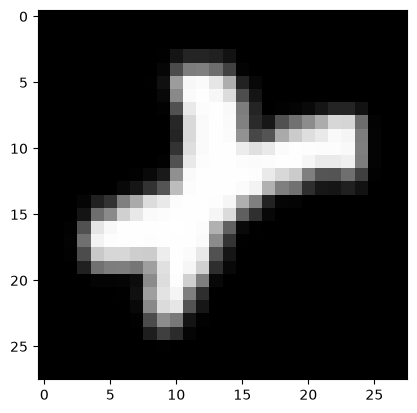

In [77]:
imagen_E = E_entrenar.data[10].numpy()
plt.imshow(imagen_E, cmap="gray")
plt.show()


In [101]:
r_i_E = E_entrenar.targets[10].item()
p(nombres_emnist[r_i_E])

t


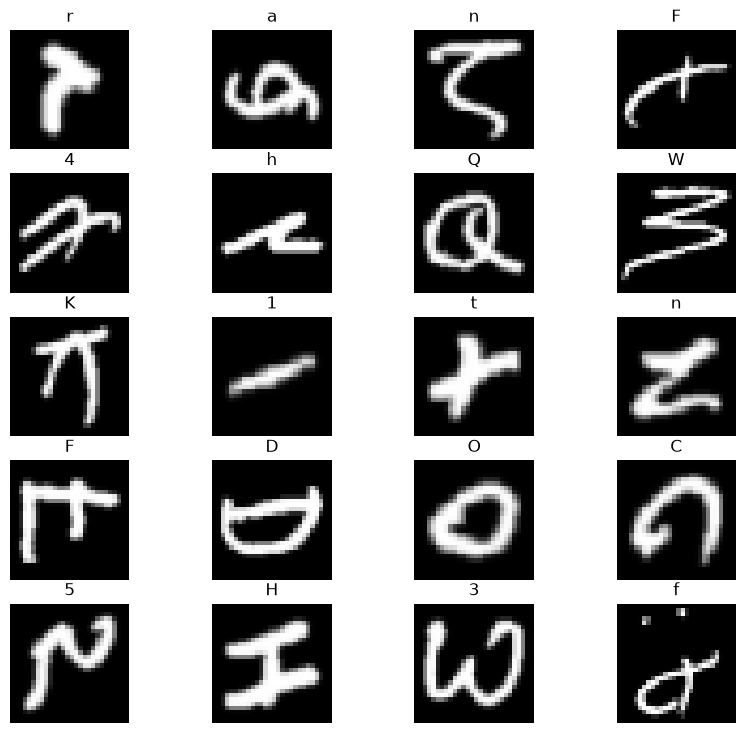

In [102]:
plt.figure(figsize=(10,9))
for i in range (20):
    imagen_E=E_entrenar.data[i].numpy()
    r_i_E= E_entrenar.targets[i].item()
    plt.subplot(5,4,i+1)
    plt.title(nombres_emnist[r_i_E])
    plt.axis("off")
    plt.imshow(imagen_E, cmap="gray")
plt.show()

### enderezar las imágenes de EMNIST, que vienen giradas

In [103]:
imagenes_E_entrenar = E_entrenar.data.numpy().transpose(0, 2, 1)
imagenes_E_prueba = E_prueba.data.numpy().transpose(0, 2, 1)
p(imagenes_E_entrenar.shape)

(112800, 28, 28)


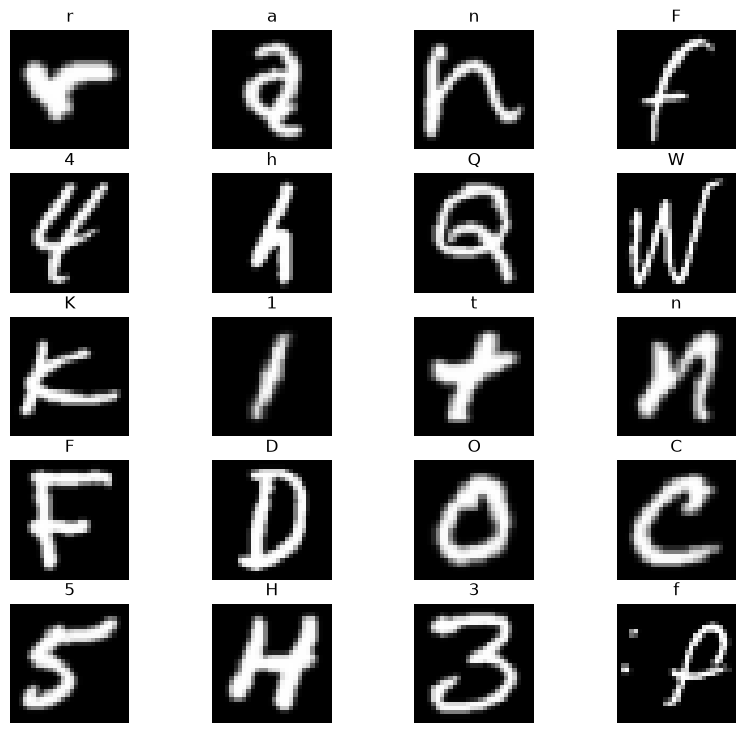

In [104]:
plt.figure(figsize=(10,9))
for i in range (20):
    imagen_E = imagenes_E_entrenar[i]
    r_i_E = E_entrenar.targets[i].item()
    plt.subplot(5,4,i+1)
    plt.title(nombres_emnist[r_i_E])
    plt.axis("off")
    plt.imshow(imagen_E, cmap="gray")
plt.show()

### lo convertimos a data frame

In [105]:
df_e_emnist = pd.DataFrame(imagenes_E_entrenar.reshape(112800, 784))
df_e_emnist["respuesta"] = E_entrenar.targets.numpy()
df_e_emnist.head()

,0,1,2,3,4,5,6,7,8,9,...,775,776,777,778,779,780,781,782,783,respuesta
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,45
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,36
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,43
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,15
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,4


In [106]:
df_e_emnist.shape

(112800, 785)

### Tabla de prueba

In [107]:
df_p_emnist = pd.DataFrame(imagenes_E_prueba.reshape(18800, 784))
df_p_emnist["respuesta"] = E_prueba.targets.numpy()
df_p_emnist.head()

,0,1,2,3,4,5,6,7,8,9,...,775,776,777,778,779,780,781,782,783,respuesta
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,41
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,39
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,9
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,26
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,44


In [108]:
df_p_emnist.shape


(18800, 785)

### Describir

In [111]:
d(df_e_emnist.describe())
p("\n")
p("*--"*45)
p("\n")
d(df_p_emnist.describe())

,0,1,2,3,4,5,6,7,8,9,...,775,776,777,778,779,780,781,782,783,respuesta
count,112800.0,112800.0,112800.0,112800.0,112800.0,112800.0,112800.0,112800.0,112800.0,112800.0,...,112800.0,112800.0,112800.0,112800.0,112800.0,112800.0,112800.0,112800.0,112800.0,112800.00000
mean,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,23.00000
std,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,13.56472
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00000
25%,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,11.00000
50%,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,23.00000
75%,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,35.00000
max,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,46.00000




*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--




,0,1,2,3,4,5,6,7,8,9,...,775,776,777,778,779,780,781,782,783,respuesta
count,18800.0,18800.0,18800.0,18800.0,18800.0,18800.0,18800.0,18800.0,18800.0,18800.0,...,18800.0,18800.0,18800.0,18800.0,18800.0,18800.0,18800.0,18800.0,18800.0,18800.000000
mean,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,23.000000
std,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,13.565021
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
25%,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,11.000000
50%,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,23.000000
75%,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,35.000000
max,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,46.000000


In [112]:
p("Entrenamiento:", df_e_emnist.shape)
p("Prueba:", df_p_emnist.shape)

Entrenamiento: (112800, 785)
Prueba: (18800, 785)


### Separar en X e Y

In [113]:
Xtr = df_e_emnist.drop(columns="respuesta")
Ytr = df_e_emnist["respuesta"]
Xts = df_p_emnist.drop(columns="respuesta")
Yts = df_p_emnist["respuesta"]

p("Datos de entrenamiento: ", len(Xtr))
p("Datos de prueba: ", len(Xts))

Datos de entrenamiento:  112800
Datos de prueba:  18800


### Guardar

In [114]:
df_e_emnist.to_csv(Carpeta_listos/"emnist_entrenamiento.csv", index=False)
df_p_emnist.to_csv(Carpeta_listos/"emnist_prueba.csv", index=False)
pd.Series(nombres_emnist).to_csv(Carpeta_listos/"nombres_emnist.csv", index=False)
p("Guardado")

Guardado


# Animales

### la lista de animales

In [115]:
animales = {
    "cat": "gato", "dog": "perro", "fish": "pez", "bird": "pájaro",
    "rabbit": "conejo", "horse": "caballo", "cow": "vaca", "pig": "cerdo",
    "elephant": "elefante", "giraffe": "jirafa", "snake": "serpiente", "spider": "araña",
    "butterfly": "mariposa", "duck": "pato", "owl": "búho", "frog": "rana",
    "crab": "cangrejo", "octopus": "pulpo", "shark": "tiburón", "snail": "caracol"
}

nombres_animales = list(animales.values())
p(nombres_animales)

['gato', 'perro', 'pez', 'pájaro', 'conejo', 'caballo', 'vaca', 'cerdo', 'elefante', 'jirafa', 'serpiente', 'araña', 'mariposa', 'pato', 'búho', 'rana', 'cangrejo', 'pulpo', 'tiburón', 'caracol']


In [116]:
Carpeta_animals = Carpeta_descargas/"Animals"
Carpeta_animals.mkdir(parents=True, exist_ok=True)
p(Carpeta_animals)

/home/Ian/prediccion_red/Dataset/Descargados/Animals


In [117]:
lista_imagenes = []
lista_respuestas = []
numero = 0

for nombre in animales:
    archivo = Carpeta_animals/(nombre + ".npy")

    if not archivo.exists():
        url = "https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/" + nombre + ".npy"
        urllib.request.urlretrieve(url, archivo)

    dibujos = np.load(archivo, mmap_mode="r")
    lista_imagenes.append(dibujos[:6000])
    lista_respuestas.append(np.full(6000, numero))

    p(animales[nombre], "listo")
    numero = numero + 1

gato listo
perro listo
pez listo
pájaro listo
conejo listo
caballo listo
vaca listo
cerdo listo
elefante listo
jirafa listo
serpiente listo
araña listo
mariposa listo
pato listo
búho listo
rana listo
cangrejo listo
pulpo listo
tiburón listo
caracol listo


### juntar todo

In [118]:
imagenes_animales = np.concatenate(lista_imagenes)
respuestas_animales = np.concatenate(lista_respuestas)
p(imagenes_animales.shape)

(120000, 784)


### convertir los dibujos en tabla

In [119]:
df_a = pd.DataFrame(imagenes_animales)
p(df_a.shape)

(120000, 784)


In [120]:
df_a["respuesta"] = respuestas_animales
p(df_a.shape)
d(df_a.head())

(120000, 785)


,0,1,2,3,4,5,6,7,8,9,...,775,776,777,778,779,780,781,782,783,respuesta
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### ver un dibujo de cada animal

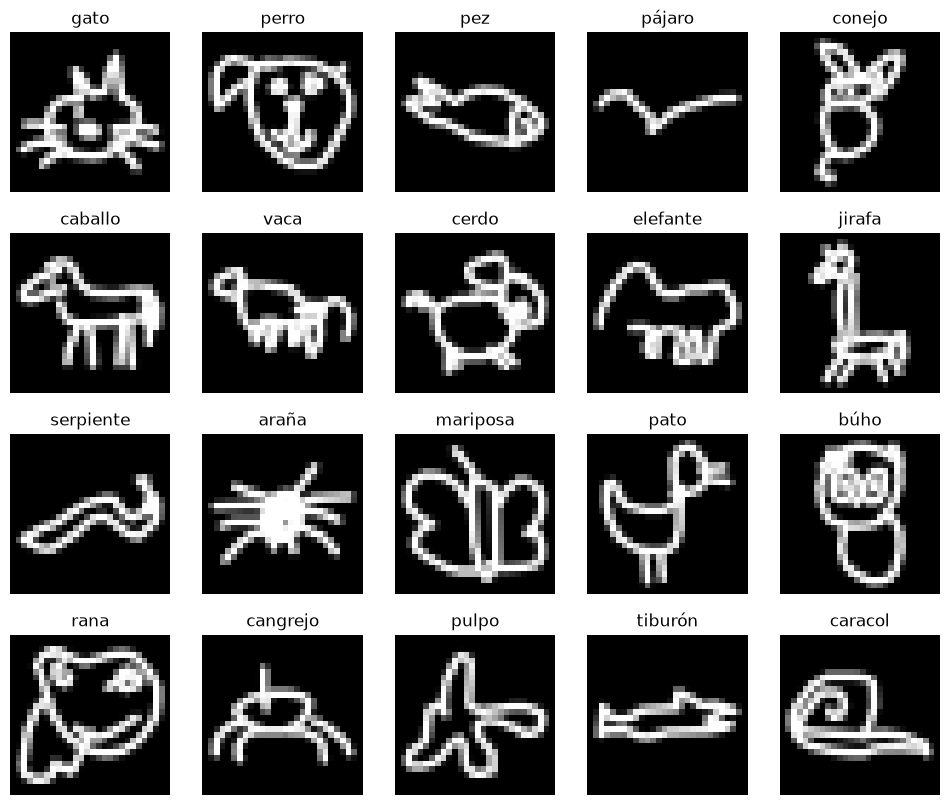

In [125]:
plt.figure(figsize=(12, 10))

for i in range(20):
    imagen_A = imagenes_animales[i * 6000].reshape(28, 28)
    r_i_A = respuestas_animales[i * 6000]

    plt.subplot(4, 5, i + 1)
    plt.imshow(imagen_A, cmap="gray")
    plt.title(nombres_animales[r_i_A])
    plt.axis("off")

plt.show()

In [126]:
p(df_a.isnull().sum())

0            0
1            0
2            0
3            0
4            0
            ..
780          0
781          0
782          0
783          0
respuesta    0
Length: 785, dtype: int64


In [127]:
d(df_a.describe())

,0,1,2,3,4,5,6,7,8,9,...,775,776,777,778,779,780,781,782,783,respuesta
count,120000.0,120000.0,120000.0,120000.0,120000.0,120000.0,120000.0,120000.0,120000.0,120000.0,...,120000.0,120000.0,120000.0,120000.0,120000.0,120000.0,120000.0,120000.0,120000.0,120000.000000
mean,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9.500000
std,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.766305
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
25%,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.750000
50%,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9.500000
75%,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,14.250000
max,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,19.000000


In [128]:
p(df_a["respuesta"].value_counts())

respuesta
0     6000
1     6000
2     6000
3     6000
4     6000
5     6000
6     6000
7     6000
8     6000
9     6000
10    6000
11    6000
12    6000
13    6000
14    6000
15    6000
16    6000
17    6000
18    6000
19    6000
Name: count, dtype: int64


### separar X e Y

In [129]:
X = df_a.drop(columns="respuesta")
Y = df_a["respuesta"]
p("X:", X.shape)
p("Y:", Y.shape)

X: (120000, 784)
Y: (120000,)


### separar entrenamiento y prueba

In [130]:
Xtr, Xts, Ytr, Yts = train_test_split(X, Y, test_size=0.20, random_state=42, stratify=Y)
p("Entrenamiento:", Xtr.shape)
p("Prueba:", Xts.shape)

Entrenamiento: (96000, 784)
Prueba: (24000, 784)


In [131]:
p(Ytr.value_counts())

respuesta
11    4800
12    4800
15    4800
14    4800
7     4800
10    4800
3     4800
13    4800
0     4800
18    4800
2     4800
17    4800
8     4800
9     4800
4     4800
6     4800
5     4800
19    4800
16    4800
1     4800
Name: count, dtype: int64


In [132]:
df_a.to_csv(Carpeta_listos/"animales.csv", index=False)
pd.Series(nombres_animales).to_csv(Carpeta_listos/"nombres_animales.csv", index=False)
p("Guardado")

Guardado
